# Part 2: The SEIR Model

## Adding a Latency Period

---

## The Latency Problem

In the SIR model, infected individuals **immediately** become infectious.

But for many diseases, this isn't realistic:
- **COVID-19**: 2-14 day incubation period
- **Influenza**: 1-4 day incubation
- **Measles**: 10-14 day incubation

### Question
**Can people infect others immediately after being infected?**

**Answer**: No. There's typically a **latency period** or **incubation period** during which:
- The person has been infected
- But is **not yet infectious**

The SIR model cannot capture this. We need a new state.

In [2]:
# Setup
import sys
sys.path.append('../src')

import numpy as np
import matplotlib.pyplot as plt

from seir import seir_rhs, simulate_seir, plot_seir
from sir import simulate_sir
from utils import find_peak
from visualisation import plot_comparison

np.random.seed(42)
print("✓ Setup complete")

✓ Setup complete


## 2.1 Introducing the Exposed State

We add a new compartment: **E(t)** — Exposed

### State Flow

```
S → E → I → R
```

- **S → E**: Susceptible individuals get infected (exposed)
- **E → I**: Exposed individuals become infectious after latency period
- **I → R**: Infectious individuals recover

### New Parameter: σ (sigma)

- **σ** = rate of progression from E to I
- **1/σ** = average latency period

Examples:
- σ = 0.2 per day → latency period = 5 days
- σ = 0.5 per day → latency period = 2 days

## 2.2 Deriving SEIR Equations

### Rate of change of S
Same as SIR:
$$\frac{dS}{dt} = -\beta \frac{S \cdot I}{N}$$

### Rate of change of E
**Increases** from new infections, **decreases** from progression to infectious:
$$\frac{dE}{dt} = \beta \frac{S \cdot I}{N} - \sigma E$$

### Rate of change of I
**Increases** from exposed becoming infectious, **decreases** from recovery:
$$\frac{dI}{dt} = \sigma E - \gamma I$$

### Rate of change of R
Same as SIR:
$$\frac{dR}{dt} = \gamma I$$

---

### Conservation Check
$$\frac{d(S+E+I+R)}{dt} = 0$$

## Figure 7: SEIR Trajectories

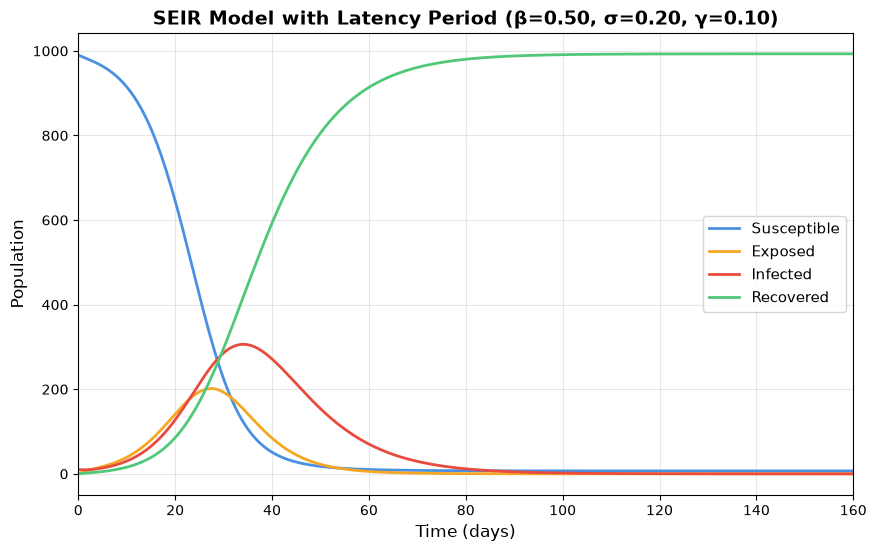

SEIR Epidemic:
  Peak time: 34.1 days
  Peak infected: 306
  Latency period: 5.0 days


In [3]:
# Parameters
beta = 0.5
sigma = 0.2  # 5-day latency
gamma = 0.1
N = 1000

# Initial conditions
S0 = 990
E0 = 0
I0 = 10
R0 = 0

# Simulate
solution = simulate_seir(beta, sigma, gamma, S0, E0, I0, R0, t_span=(0, 160))

# Plot
fig, ax = plt.subplots(figsize=(10, 6))
plot_seir(solution, beta=beta, sigma=sigma, gamma=gamma, 
          title="SEIR Model with Latency Period", ax=ax)
plt.show()

# Analysis
t = solution.t
S, E, I, R = solution.y
peak_time, peak_value, _ = find_peak(t, I)

print(f"SEIR Epidemic:")
print(f"  Peak time: {peak_time:.1f} days")
print(f"  Peak infected: {peak_value:.0f}")
print(f"  Latency period: {1/sigma:.1f} days")

## 2.3 Comparing SIR and SEIR

What's the effect of adding a latency period?

## Figure 8: SIR vs SEIR Comparison

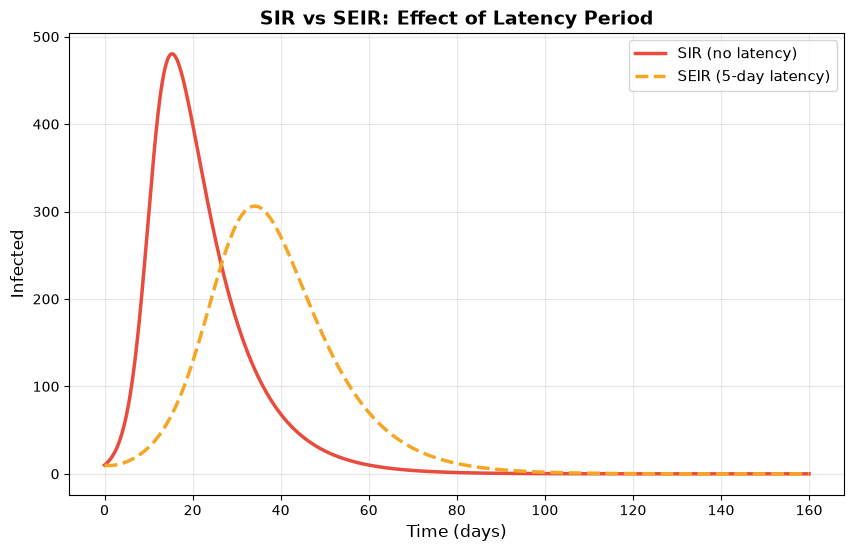

Comparison:
  SIR  peak: t=15.4, I=480
  SEIR peak: t=34.1, I=306
  Peak delay: 18.7 days
  Peak reduction: 174 people


In [4]:
# Run both models with same parameters
sir_sol = simulate_sir(beta, gamma, S0, I0, R0, t_span=(0, 160))
seir_sol = simulate_seir(beta, sigma, gamma, S0, E0, I0, R0, t_span=(0, 160))

# Extract infected populations
t_sir = sir_sol.t
I_sir = sir_sol.y[1]

t_seir = seir_sol.t
I_seir = seir_sol.y[2]

# Plot comparison
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(t_sir, I_sir, label='SIR (no latency)', linewidth=2.5, color='#E94B3C')
ax.plot(t_seir, I_seir, label='SEIR (5-day latency)', linewidth=2.5, 
        color='#F5A623', linestyle='--')

ax.set_xlabel('Time (days)', fontsize=12)
ax.set_ylabel('Infected', fontsize=12)
ax.set_title('SIR vs SEIR: Effect of Latency Period', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.show()

# Compare peaks
sir_peak_time, sir_peak_val, _ = find_peak(t_sir, I_sir)
seir_peak_time, seir_peak_val, _ = find_peak(t_seir, I_seir)

print("Comparison:")
print(f"  SIR  peak: t={sir_peak_time:.1f}, I={sir_peak_val:.0f}")
print(f"  SEIR peak: t={seir_peak_time:.1f}, I={seir_peak_val:.0f}")
print(f"  Peak delay: {seir_peak_time - sir_peak_time:.1f} days")
print(f"  Peak reduction: {sir_peak_val - seir_peak_val:.0f} people")

## Figure 9: Peak Timing Comparison

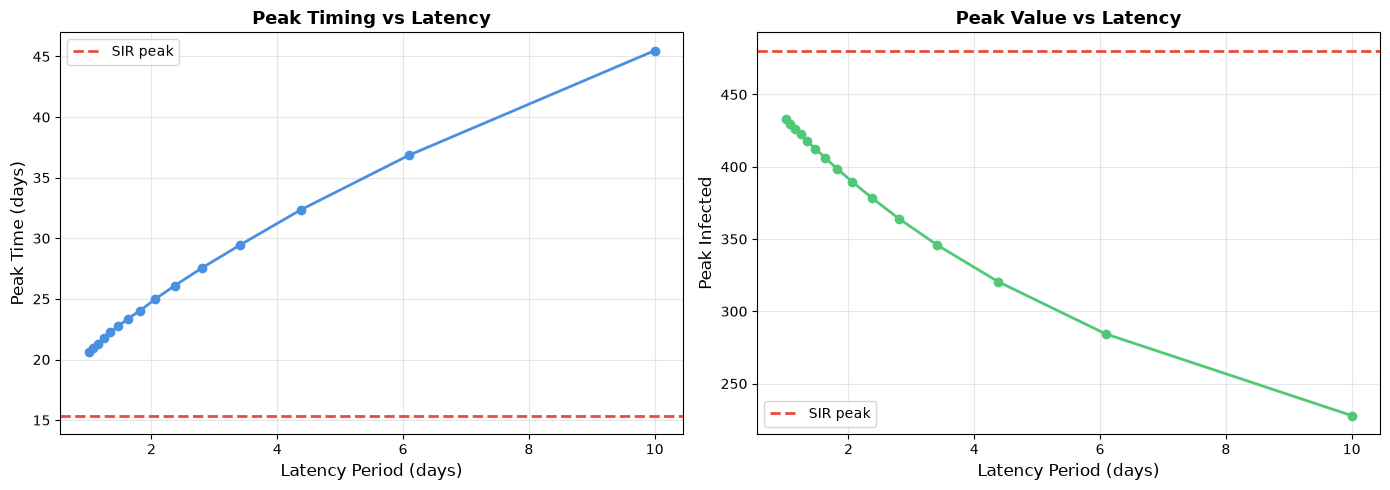

Longer latency → delayed peak, slightly lower peak value


In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left: Peak time vs sigma
sigma_values = np.linspace(0.1, 1.0, 15)
peak_times = []

for sig in sigma_values:
    sol = simulate_seir(beta, sig, gamma, S0, E0, I0, R0, t_span=(0, 160))
    I_vals = sol.y[2]
    t_vals = sol.t
    pk_time, _, _ = find_peak(t_vals, I_vals)
    peak_times.append(pk_time)

latency_periods = 1 / sigma_values

ax1.plot(latency_periods, peak_times, 'o-', linewidth=2, markersize=6, color='#4A90E2')
ax1.axhline(y=sir_peak_time, color='#E94B3C', linestyle='--', linewidth=2, label='SIR peak')
ax1.set_xlabel('Latency Period (days)', fontsize=12)
ax1.set_ylabel('Peak Time (days)', fontsize=12)
ax1.set_title('Peak Timing vs Latency', fontsize=13, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

# Right: Peak value vs sigma
peak_values = []

for sig in sigma_values:
    sol = simulate_seir(beta, sig, gamma, S0, E0, I0, R0, t_span=(0, 160))
    I_vals = sol.y[2]
    peak_values.append(I_vals.max())

ax2.plot(latency_periods, peak_values, 'o-', linewidth=2, markersize=6, color='#50C878')
ax2.axhline(y=sir_peak_val, color='#E94B3C', linestyle='--', linewidth=2, label='SIR peak')
ax2.set_xlabel('Latency Period (days)', fontsize=12)
ax2.set_ylabel('Peak Infected', fontsize=12)
ax2.set_title('Peak Value vs Latency', fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Longer latency → delayed peak, slightly lower peak value")

## Figure 10: Varying Latency Period (σ)

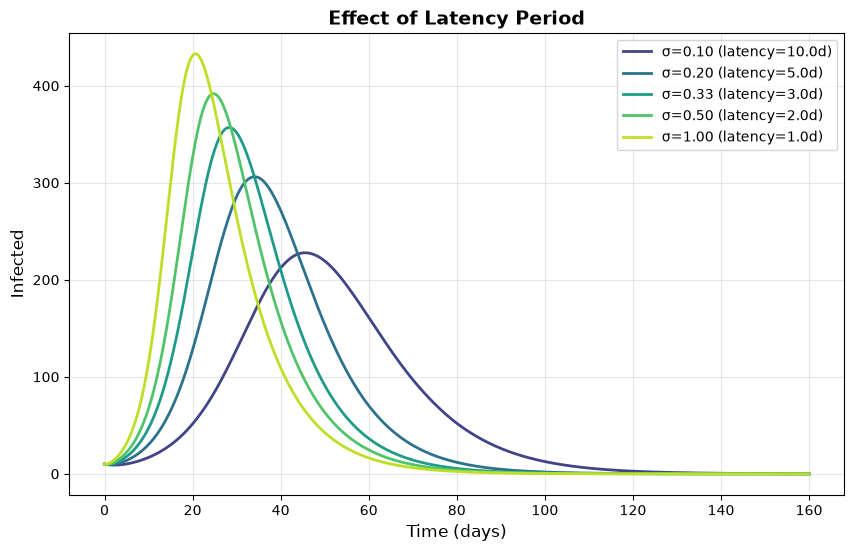

Shorter latency (higher σ) → faster dynamics, approaches SIR behavior


In [6]:
fig, ax = plt.subplots(figsize=(10, 6))

sigma_values = [0.1, 0.2, 0.33, 0.5, 1.0]
colors = plt.cm.viridis(np.linspace(0.2, 0.9, len(sigma_values)))

for i, sig in enumerate(sigma_values):
    sol = simulate_seir(beta, sig, gamma, S0, E0, I0, R0, t_span=(0, 160))
    t = sol.t
    I_vals = sol.y[2]
    latency = 1/sig
    ax.plot(t, I_vals, label=f'σ={sig:.2f} (latency={latency:.1f}d)', 
            linewidth=2, color=colors[i])

ax.set_xlabel('Time (days)', fontsize=12)
ax.set_ylabel('Infected', fontsize=12)
ax.set_title('Effect of Latency Period', fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.show()

print("Shorter latency (higher σ) → faster dynamics, approaches SIR behavior")

## Summary

### What We Added
- **Exposed (E) compartment**: infected but not yet infectious
- **Parameter σ**: rate of progression from exposed to infectious
- **Latency period**: 1/σ

### Key Findings
1. **Latency delays the epidemic** — peak occurs later
2. **Latency slightly reduces peak** — epidemic spreads more slowly initially
3. **As σ → ∞** (instant progression), SEIR → SIR

### When to Use SEIR
- Diseases with significant incubation period (COVID-19, measles, etc.)
- When timing of interventions matters
- When modeling exposed populations explicitly

---

## Still Missing

Both SIR and SEIR assume **homogeneous mixing**:
- Everyone meets everyone equally
- No social structure
- No spatial constraints

**Next**: We'll model disease spread on **networks** where contacts are explicitly defined.